# AdaBoost on baseline.csv (Predict DX at M06)

In [ ]:
import pandas as pd
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV

# Load the data
data = pd.read_csv('C:/Users/student/bl(lessexc).csv')

In [ ]:
#### Data Splitting

In [22]:
# Create the training and testing feature and label sets
x = data.iloc[:,1:-1] # independent features
y = data.iloc[:,-1] # dependent feature
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.30, random_state=42)

In [23]:
x_train

,AGE,PTEDUCAT,APOE4,CDRSB,ADAS11,ADAS13,MMSE,RAVLT_immediate,RAVLT_learning,RAVLT_perc_forgetting,...,ST43TS_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST23CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST30SV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST73CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ABETA_UPENNBIOMK9_04_19_17,TAU_UPENNBIOMK9_04_19_17,PTAU_UPENNBIOMK9_04_19_17,PTGENDER_Female,PTGENDER_Male,DX
351,83.3,14,1,3.5,9.33,15.33,26,32.0,4.0,87.5000,...,0.575,1399.0,1369.0,2557.0,843.300000,549.200000,54.940000,1,0,0
649,68.2,14,1,1.5,9.00,13.00,30,38.0,6.0,36.3636,...,0.633,2323.0,1135.0,2304.0,695.300000,237.700000,22.110000,1,0,1
1038,81.6,16,0,3.0,9.00,18.00,26,29.0,1.0,100.0000,...,0.587,2971.0,2567.0,1942.0,1459.000000,250.100000,21.350000,1,0,1
249,71.6,14,1,7.0,24.00,34.00,20,28.0,1.0,100.0000,...,0.545,2380.0,1817.0,1415.0,1064.913718,284.614621,27.130365,0,1,0
784,59.0,16,0,2.0,13.00,16.00,29,44.0,4.0,27.2727,...,0.525,2705.0,251.0,2054.0,1535.000000,142.500000,12.620000,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
330,80.3,18,1,0.0,7.67,10.67,28,37.0,7.0,10.0000,...,0.672,2478.0,377.0,1943.0,1064.913718,284.614621,27.130365,1,0,2
466,71.1,13,0,5.0,21.00,34.00,23,20.0,1.0,75.0000,...,0.659,1244.0,825.0,2647.0,1064.913718,284.614621,27.130365,1,0,0
121,85.5,20,1,6.0,16.67,22.67,26,26.0,5.0,75.0000,...,0.485,2187.0,2902.0,1581.0,1064.913718,284.614621,27.130365,0,1,0
1044,55.9,19,0,2.5,11.00,20.00,30,33.0,7.0,70.0000,...,0.535,2590.0,881.0,1770.0,927.500000,106.300000,8.870000,0,1,1


In [ ]:
#### Hyperparameter Tuning

In [24]:
# Define the hyperparameter grid
param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.1, 0.5, 1.0, 2.0],
    'algorithm': ['SAMME', 'SAMME.R']
}

In [25]:
# Create an AdaBoost classifier
clf = AdaBoostClassifier(random_state=1)

# Create a grid search object
grid_search = GridSearchCV(clf, param_grid=param_grid, cv=5, n_jobs=-1)

In [26]:
# Fit the grid search object to the training data
grid_search.fit(x_train, y_train)

GridSearchCV(cv=5, estimator=AdaBoostClassifier(random_state=1), n_jobs=-1,
             param_grid={'algorithm': ['SAMME', 'SAMME.R'],
                         'learning_rate': [0.1, 0.5, 1.0, 2.0],
                         'n_estimators': [50, 100, 200]})

In [27]:
# Print the best parameters and the corresponding mean cross-validated score
print("Best parameters:", grid_search.best_params_)
print("Best score:", grid_search.best_score_)

Best parameters: {'algorithm': 'SAMME', 'learning_rate': 0.1, 'n_estimators': 50}
Best score: 0.9712246302029584


In [ ]:
#### Model Training

In [28]:
# Train an AdaBoost classifier on the training set with the best hyperparameters
clf = AdaBoostClassifier(**grid_search.best_params_)
clf.fit(x_train, y_train)

AdaBoostClassifier(algorithm='SAMME', learning_rate=0.1)

In [ ]:
#### Model Testing

In [29]:
# Make predictions on the training and testing sets
y_train_pred = clf.predict(x_train)
y_test_pred = clf.predict(x_test)
y_prob = clf.predict_proba(x_test)

In [30]:
# Evaluate the performance of the classifier
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print("Training accuracy:", train_accuracy)
print("Testing accuracy:", test_accuracy)

confusion = confusion_matrix(y_test, y_test_pred)
print("Confusion matrix:\n", confusion)

Training accuracy: 0.9712041884816754
Testing accuracy: 0.9695121951219512
Confusion matrix:
 [[ 49   9   0]
 [  0 163   1]
 [  0   0 106]]


In [31]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       1.00      0.84      0.92        58
           1       0.95      0.99      0.97       164
           2       0.99      1.00      1.00       106

    accuracy                           0.97       328
   macro avg       0.98      0.95      0.96       328
weighted avg       0.97      0.97      0.97       328



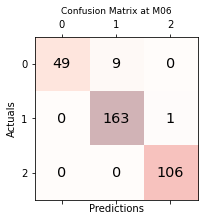

In [32]:
conf_matrix = confusion_matrix(y_true=y_test, y_pred=y_test_pred)
#
# Print the confusion matrix using Matplotlib
#
fig, ax = plt.subplots(figsize=(3, 3))
ax.matshow(conf_matrix, cmap=plt.cm.Reds, alpha=0.3)
for i in range(conf_matrix.shape[0]):
    for j in range(conf_matrix.shape[1]):
        ax.text(x=j, y=i,s=conf_matrix[i, j], va='center', ha='center', size='x-large')
 
plt.xlabel('Predictions', fontsize=10)
plt.ylabel('Actuals', fontsize=10)
plt.title('Confusion Matrix at M06', fontsize=9)
plt.show()

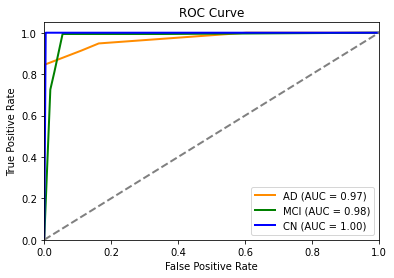

In [44]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.preprocessing import label_binarize
from sklearn.metrics import auc

# Binarize the labels
y_binarized = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_binarized.shape[1]

# Compute ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_binarized[:, i], y_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute macro-average ROC curve and AUC
fpr["macro"], tpr["macro"], _ = roc_curve(y_binarized.ravel(), y_prob.ravel())
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# Plot ROC curves
plt.figure()
plt.plot(fpr[0], tpr[0], color='darkorange', lw=2,
         label='AD (AUC = %0.2f)' % roc_auc[0])
plt.plot(fpr[1], tpr[1], color='green', lw=2,
         label='MCI (AUC = %0.2f)' % roc_auc[1])
plt.plot(fpr[2], tpr[2], color='blue', lw=2,
         label='CN (AUC = %0.2f)' % roc_auc[2])
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()
plt.show()

# bl&m06.csv (Predict DX at M12)

In [33]:
import pandas as pd
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV

# Load the data
data = pd.read_csv('C:/Users/student/bl&m06(lessexc).csv')

In [34]:
# Create the training and testing feature and label sets
x = data.iloc[:,1:-1] # independent features
y = data.iloc[:,-1] # dependent feature
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.30, random_state=42)

# Define the hyperparameter grid
param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.1, 0.5, 1.0, 2.0],
    'algorithm': ['SAMME', 'SAMME.R']
}

# Create an AdaBoost classifier
clf = AdaBoostClassifier(random_state=1)

# Create a grid search object
grid_search = GridSearchCV(clf, param_grid=param_grid, cv=5, n_jobs=-1)

In [35]:
# Fit the grid search object to the training data
grid_search.fit(x_train, y_train)

GridSearchCV(cv=5, estimator=AdaBoostClassifier(random_state=1), n_jobs=-1,
             param_grid={'algorithm': ['SAMME', 'SAMME.R'],
                         'learning_rate': [0.1, 0.5, 1.0, 2.0],
                         'n_estimators': [50, 100, 200]})

In [36]:
# Print the best parameters and the corresponding mean cross-validated score
print("Best parameters:", grid_search.best_params_)
print("Best score:", grid_search.best_score_)

# Train an AdaBoost classifier on the training set with the best hyperparameters
clf = AdaBoostClassifier(**grid_search.best_params_)
clf.fit(x_train, y_train)

# Make predictions on the training and testing sets
y_train_pred = clf.predict(x_train)
y_test_pred = clf.predict(x_test)
y_prob = clf.predict_proba(x_test)

# Evaluate the performance of the classifier
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print("Training accuracy:", train_accuracy)
print("Testing accuracy:", test_accuracy)

confusion = confusion_matrix(y_test, y_test_pred)
print("Confusion matrix:\n", confusion)

Best parameters: {'algorithm': 'SAMME', 'learning_rate': 0.1, 'n_estimators': 50}
Best score: 0.9489508083935329
Training accuracy: 0.9489528795811518
Testing accuracy: 0.9603658536585366
Confusion matrix:
 [[ 58  12   0]
 [  0 152   1]
 [  0   0 105]]


In [37]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       1.00      0.83      0.91        70
           1       0.93      0.99      0.96       153
           2       0.99      1.00      1.00       105

    accuracy                           0.96       328
   macro avg       0.97      0.94      0.95       328
weighted avg       0.96      0.96      0.96       328



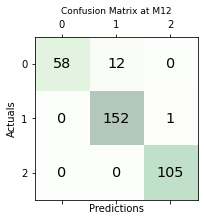

In [38]:
conf_matrix = confusion_matrix(y_true=y_test, y_pred=y_test_pred)
#
# Print the confusion matrix using Matplotlib
#
fig, ax = plt.subplots(figsize=(3, 3))
ax.matshow(conf_matrix, cmap=plt.cm.Greens, alpha=0.3)
for i in range(conf_matrix.shape[0]):
    for j in range(conf_matrix.shape[1]):
        ax.text(x=j, y=i,s=conf_matrix[i, j], va='center', ha='center', size='x-large')
 
plt.xlabel('Predictions', fontsize=10)
plt.ylabel('Actuals', fontsize=10)
plt.title('Confusion Matrix at M12', fontsize=9)
plt.show()

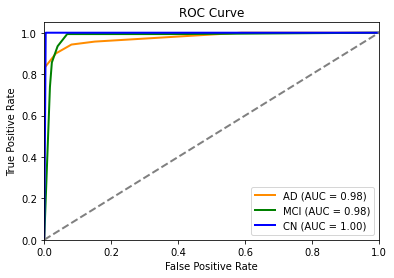

In [8]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.preprocessing import label_binarize
from sklearn.metrics import auc

# Binarize the labels
y_binarized = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_binarized.shape[1]

# Compute ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_binarized[:, i], y_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute macro-average ROC curve and AUC
fpr["macro"], tpr["macro"], _ = roc_curve(y_binarized.ravel(), y_prob.ravel())
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# Plot ROC curves
plt.figure()
plt.plot(fpr[0], tpr[0], color='darkorange', lw=2,
         label='AD (AUC = %0.2f)' % roc_auc[0])
plt.plot(fpr[1], tpr[1], color='green', lw=2,
         label='MCI (AUC = %0.2f)' % roc_auc[1])
plt.plot(fpr[2], tpr[2], color='blue', lw=2,
         label='CN (AUC = %0.2f)' % roc_auc[2])
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()
plt.show()

# bl&m06&m12.csv (Predict DX at M18)

In [9]:
import pandas as pd
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV

# Load the data
data = pd.read_csv('C:/Users/student/bl&m06&m12(lessexc).csv')

# Create the training and testing feature and label sets
x = data.iloc[:,1:-1] # independent features
y = data.iloc[:,-1] # dependent feature
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.30, random_state=42)

# Define the hyperparameter grid
param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.1, 0.5, 1.0, 2.0],
    'algorithm': ['SAMME', 'SAMME.R']
}

# Create an AdaBoost classifier
clf = AdaBoostClassifier(random_state=1)

# Create a grid search object
grid_search = GridSearchCV(clf, param_grid=param_grid, cv=5, n_jobs=-1)

In [10]:
# Fit the grid search object to the training data
grid_search.fit(x_train, y_train)

GridSearchCV(cv=5, estimator=AdaBoostClassifier(random_state=1), n_jobs=-1,
             param_grid={'algorithm': ['SAMME', 'SAMME.R'],
                         'learning_rate': [0.1, 0.5, 1.0, 2.0],
                         'n_estimators': [50, 100, 200]})

In [11]:
# Print the best parameters and the corresponding mean cross-validated score
print("Best parameters:", grid_search.best_params_)
print("Best score:", grid_search.best_score_)

# Train an AdaBoost classifier on the training set with the best hyperparameters
clf = AdaBoostClassifier(**grid_search.best_params_)
clf.fit(x_train, y_train)

# Make predictions on the training and testing sets
y_train_pred = clf.predict(x_train)
y_test_pred = clf.predict(x_test)
y_prob = clf.predict_proba(x_test)

# Evaluate the performance of the classifier
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print("Training accuracy:", train_accuracy)
print("Testing accuracy:", test_accuracy)

confusion = confusion_matrix(y_test, y_test_pred)
print("Confusion matrix:\n", confusion)

Best parameters: {'algorithm': 'SAMME', 'learning_rate': 0.5, 'n_estimators': 200}
Best score: 0.9816735466116272
Training accuracy: 1.0
Testing accuracy: 0.9512195121951219
Confusion matrix:
 [[ 72  11   0]
 [  5 135   0]
 [  0   0 105]]


In [12]:
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.94      0.87      0.90        83
           1       0.92      0.96      0.94       140
           2       1.00      1.00      1.00       105

    accuracy                           0.95       328
   macro avg       0.95      0.94      0.95       328
weighted avg       0.95      0.95      0.95       328



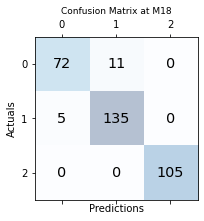

In [15]:
conf_matrix = confusion_matrix(y_true=y_test, y_pred=y_test_pred)
#
# Print the confusion matrix using Matplotlib
#
fig, ax = plt.subplots(figsize=(3, 3))
ax.matshow(conf_matrix, cmap=plt.cm.Blues, alpha=0.3)
for i in range(conf_matrix.shape[0]):
    for j in range(conf_matrix.shape[1]):
        ax.text(x=j, y=i,s=conf_matrix[i, j], va='center', ha='center', size='x-large')
 
plt.xlabel('Predictions', fontsize=10)
plt.ylabel('Actuals', fontsize=10)
plt.title('Confusion Matrix at M18', fontsize=9)
plt.show()

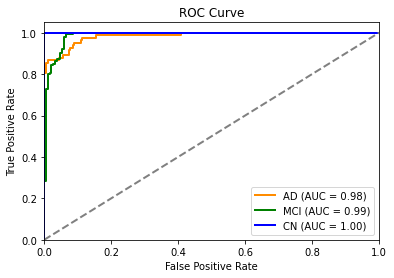

In [14]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.preprocessing import label_binarize
from sklearn.metrics import auc

# Binarize the labels
y_binarized = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_binarized.shape[1]

# Compute ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_binarized[:, i], y_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute macro-average ROC curve and AUC
fpr["macro"], tpr["macro"], _ = roc_curve(y_binarized.ravel(), y_prob.ravel())
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# Plot ROC curves
plt.figure()
plt.plot(fpr[0], tpr[0], color='darkorange', lw=2,
         label='AD (AUC = %0.2f)' % roc_auc[0])
plt.plot(fpr[1], tpr[1], color='green', lw=2,
         label='MCI (AUC = %0.2f)' % roc_auc[1])
plt.plot(fpr[2], tpr[2], color='blue', lw=2,
         label='CN (AUC = %0.2f)' % roc_auc[2])
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()
plt.show()

# bl&m06&m12&m18.csv (Predict DX at M24)

In [16]:
import pandas as pd
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV

# Load the data
data = pd.read_csv('C:/Users/student/bl&m06&m12&m18(lessexc).csv')

# Create the training and testing feature and label sets
x = data.iloc[:,1:-1] # independent features
y = data.iloc[:,-1] # dependent feature
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.30, random_state=42)

# Define the hyperparameter grid
param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.1, 0.5, 1.0, 2.0],
    'algorithm': ['SAMME', 'SAMME.R']
}

# Create an AdaBoost classifier
clf = AdaBoostClassifier(random_state=1)

# Create a grid search object
grid_search = GridSearchCV(clf, param_grid=param_grid, cv=5, n_jobs=-1)

In [17]:
# Fit the grid search object to the training data
grid_search.fit(x_train, y_train)

GridSearchCV(cv=5, estimator=AdaBoostClassifier(random_state=1), n_jobs=-1,
             param_grid={'algorithm': ['SAMME', 'SAMME.R'],
                         'learning_rate': [0.1, 0.5, 1.0, 2.0],
                         'n_estimators': [50, 100, 200]})

In [18]:
# Print the best parameters and the corresponding mean cross-validated score
print("Best parameters:", grid_search.best_params_)
print("Best score:", grid_search.best_score_)

# Train an AdaBoost classifier on the training set with the best hyperparameters
clf = AdaBoostClassifier(**grid_search.best_params_)
clf.fit(x_train, y_train)

# Make predictions on the training and testing sets
y_train_pred = clf.predict(x_train)
y_test_pred = clf.predict(x_test)
y_prob = clf.predict_proba(x_test)

# Evaluate the performance of the classifier
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print("Training accuracy:", train_accuracy)
print("Testing accuracy:", test_accuracy)

confusion = confusion_matrix(y_test, y_test_pred)
print("Confusion matrix:\n", confusion)

Best parameters: {'algorithm': 'SAMME', 'learning_rate': 0.1, 'n_estimators': 50}
Best score: 0.9345287237702099
Training accuracy: 0.9345549738219895
Testing accuracy: 0.9146341463414634
Confusion matrix:
 [[ 83  24   0]
 [  0 116   4]
 [  0   0 101]]


In [19]:
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       1.00      0.78      0.87       107
           1       0.83      0.97      0.89       120
           2       0.96      1.00      0.98       101

    accuracy                           0.91       328
   macro avg       0.93      0.91      0.92       328
weighted avg       0.93      0.91      0.91       328



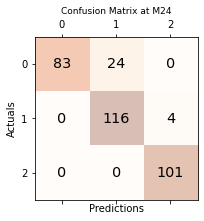

In [20]:
conf_matrix = confusion_matrix(y_true=y_test, y_pred=y_test_pred)
#
# Print the confusion matrix using Matplotlib
#
fig, ax = plt.subplots(figsize=(3, 3))
ax.matshow(conf_matrix, cmap=plt.cm.Oranges, alpha=0.3)
for i in range(conf_matrix.shape[0]):
    for j in range(conf_matrix.shape[1]):
        ax.text(x=j, y=i,s=conf_matrix[i, j], va='center', ha='center', size='x-large')
 
plt.xlabel('Predictions', fontsize=10)
plt.ylabel('Actuals', fontsize=10)
plt.title('Confusion Matrix at M24', fontsize=9)
plt.show()

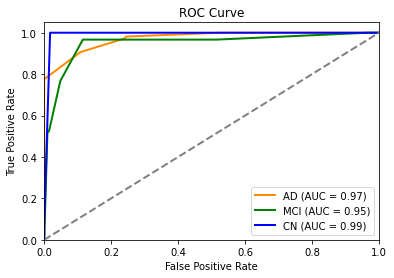

In [63]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.preprocessing import label_binarize
from sklearn.metrics import auc

# Binarize the labels
y_binarized = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_binarized.shape[1]

# Compute ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_binarized[:, i], y_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute macro-average ROC curve and AUC
fpr["macro"], tpr["macro"], _ = roc_curve(y_binarized.ravel(), y_prob.ravel())
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# Plot ROC curves
plt.figure()
plt.plot(fpr[0], tpr[0], color='darkorange', lw=2,
         label='AD (AUC = %0.2f)' % roc_auc[0])
plt.plot(fpr[1], tpr[1], color='green', lw=2,
         label='MCI (AUC = %0.2f)' % roc_auc[1])
plt.plot(fpr[2], tpr[2], color='blue', lw=2,
         label='CN (AUC = %0.2f)' % roc_auc[2])
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()
plt.show()

In [64]:
x_test

,AGE_bl,PTEDUCAT_bl,APOE4_bl,CDRSB_bl,ADAS11_bl,ADAS13_bl,MMSE_bl,RAVLT_immediate_bl,RAVLT_learning_bl,RAVLT_perc_forgetting_bl,...,ST45CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ST102CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ST43TS_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ST23CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ST30SV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ST73CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ABETA_UPENNBIOMK9_04_19_17_m18,TAU_UPENNBIOMK9_04_19_17_m18,PTAU_UPENNBIOMK9_04_19_17_m18,DX_m18
482,73.0,18,0,1.5,18.00,26.00,25,20.0,3.0,100.0000,...,3284.0,3470.0,0.632,2720.0,842.0,2438.0,687.500000,482.700000,51.640000,1
139,73.4,13,0,0.0,1.33,3.33,28,53.0,5.0,16.6667,...,3353.0,2959.0,0.621,2436.0,307.0,1854.0,1064.913718,284.614621,27.130365,2
88,64.8,20,0,1.5,4.33,9.33,29,40.0,6.0,54.5455,...,3547.0,3038.0,0.632,3527.0,847.0,1797.0,1064.913718,284.614621,27.130365,1
844,62.8,14,1,4.5,13.00,20.00,27,21.0,2.0,80.0000,...,3334.0,2872.0,0.562,2693.0,1132.0,1765.0,342.600000,140.700000,15.050000,1
730,81.8,20,0,0.0,7.00,12.00,28,27.0,4.0,12.5000,...,3195.0,2372.0,0.533,2212.0,2311.0,1800.0,925.100000,105.500000,8.260000,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
221,77.9,13,0,1.0,6.00,12.00,30,32.0,7.0,70.0000,...,3791.0,2946.0,0.586,3074.0,522.0,1509.0,611.500000,340.800000,34.400000,1
235,70.8,13,0,1.5,7.67,12.67,21,39.0,3.0,100.0000,...,3327.0,3921.0,0.605,1738.0,1086.0,1970.0,1064.913718,284.614621,27.130365,0
423,81.7,13,1,2.0,13.00,24.00,26,29.0,5.0,100.0000,...,2751.0,2857.0,0.555,1432.0,911.0,1532.0,385.400000,199.100000,19.450000,0
589,75.4,20,1,9.0,36.00,50.00,21,10.0,0.0,100.0000,...,2676.0,2769.0,0.623,2018.0,3867.0,1499.0,379.500000,355.400000,27.780000,0
